# Cyclone Operations Lab

**Milan Tony · Data science take-home**

This notebook reads the supplied workbook, validates the five-minute timeline, explores the delivered analysis, and reviews the RAG prototype. Run it from the repository root after installing `requirements.txt`. The full reproducible model fitting lives in `sensor_analysis/task1_analysis.py`; run that script to regenerate all outputs.

> Interpretation boundary: shutdowns and root causes are inferred from sensors without operator ground truth.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sensor_analysis.task1_analysis import prepare, periods
ROOT = Path.cwd()
assert (ROOT / "docs/data.xlsx").exists(), "Start Jupyter in the repository root"
plt.style.use("seaborn-v0_8-whitegrid")


## 1. Data preparation and quality

Parse numeric sensor readings while retaining counts of communication-error strings. Consolidate duplicate timestamps by median, then reindex every five minutes. Missing readings remain missing to avoid inventing operating states.


In [2]:
raw = pd.read_excel(ROOT / "docs/data.xlsx")
data, quality = prepare(raw)
summary = pd.DataFrame({"metric": ["source rows", "start", "end", "missing timestamps", "duplicate timestamps"], "value": [quality["raw_rows"], quality["start"], quality["end"], quality["missing_timestamps"], quality["duplicate_timestamps"]]})
display(summary)
display(pd.Series(quality["missing_by_sensor"], name="missing samples").to_frame())


C:\Users\milan\Desktop\Projects\ExactSpace\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,metric,value
0,source rows,377719
1,start,2017-01-01 00:00:00
2,end,2020-08-07 12:15:00
3,missing timestamps,861
4,duplicate timestamps,0


,missing samples
Cyclone_Inlet_Gas_Temp,2181
Cyclone_Material_Temp,2452
Cyclone_Outlet_Gas_draft,2182
Cyclone_cone_draft,2181
Cyclone_Gas_Outlet_Temp,2182
Cyclone_Inlet_Draft,2183


,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
count,376399.00,376128.00,376398.00,376399.00,376398.00,376397.00
mean,727.35,750.83,-177.82,-164.57,715.76,-141.30
std,328.66,350.92,99.15,90.10,325.35,77.62
min,0.00,-185.00,-456.66,-459.31,13.79,-396.37
1%,23.53,0.00,-296.63,-278.16,23.85,-236.83
5%,30.19,20.43,-277.61,-258.80,30.24,-221.12
50%,882.38,913.36,-215.26,-198.56,871.52,-169.46
95%,934.07,985.81,4.68,0.33,933.05,0.85
99%,969.86,1017.90,13.35,1.82,961.86,13.81
max,1157.63,1375.00,40.27,488.86,1375.00,41.64


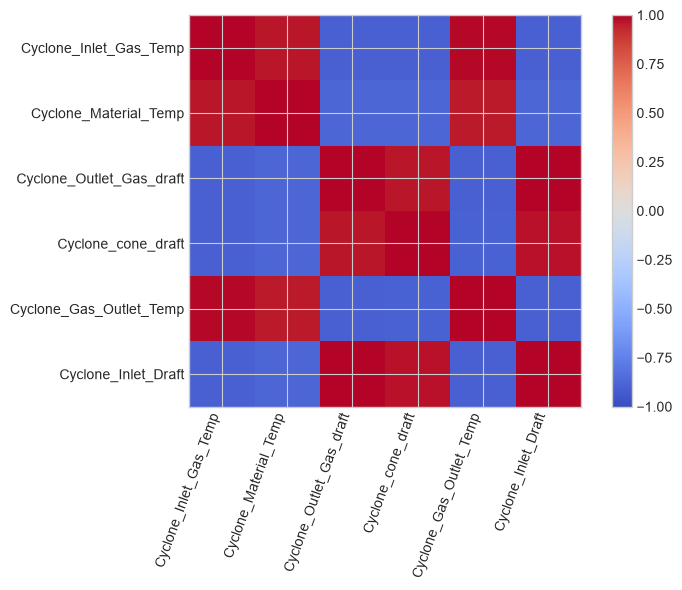

In [3]:
display(data.describe(percentiles=[.01,.05,.5,.95,.99]).round(2))
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(data.corr(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(data.columns)), data.columns, rotation=70, ha="right")
ax.set_yticks(range(len(data.columns)), data.columns)
fig.colorbar(image, ax=ax); fig.tight_layout(); plt.show()


## 2. Shutdown evidence

A shutdown proxy requires both gas temperatures below 150 and absolute inlet draft below 30 for at least 30 consecutive minutes. The threshold is a transparent rule based on the separation between hot operation and near-ambient readings. Validate it with operating logs before treating it as a formal availability KPI.


In [4]:
shutdowns = pd.read_csv(ROOT / "sensor_analysis/shutdown_periods.csv", parse_dates=["start", "end"])
candidate = (data["Cyclone_Inlet_Gas_Temp"] < 150) & (data["Cyclone_Gas_Outlet_Temp"] < 150) & (data["Cyclone_Inlet_Draft"].abs() < 30)
recomputed = periods(candidate)
recomputed = recomputed[recomputed.duration_minutes >= 30]
assert len(recomputed) == len(shutdowns), "Saved events differ from the documented rule"
print(f"Events: {len(shutdowns):,} | Detected hours: {shutdowns.duration_minutes.sum()/60:,.1f}")
display(shutdowns.groupby(shutdowns.start.dt.year).agg(events=("start", "size"), downtime_hours=("duration_minutes", lambda x: x.sum()/60)).round(1))
display(shutdowns.nlargest(10, "duration_minutes"))
display(Markdown("![2018 sensor overview](../sensor_analysis/plots/full_year.png)"))


Events: 77 | Detected hours: 5,156.4


,events,downtime_hours
start,,
2017,25,1076.8
2018,16,696.2
2019,34,2480.1
2020,2,903.2


,start,end,duration_minutes
75,2020-03-23 22:20:00,2020-04-30 13:00:00,54160
38,2018-09-26 17:20:00,2018-10-15 13:10:00,27110
54,2019-06-04 11:55:00,2019-06-20 22:10:00,23655
64,2019-09-17 08:20:00,2019-10-02 03:40:00,21320
65,2019-10-02 10:15:00,2019-10-16 19:30:00,20715
73,2019-12-11 09:25:00,2019-12-23 12:40:00,17475
10,2017-09-22 12:30:00,2017-10-03 10:00:00,15690
58,2019-08-03 09:35:00,2019-08-13 13:50:00,14655
6,2017-05-20 15:25:00,2017-05-30 04:35:00,13750
71,2019-11-30 16:00:00,2019-12-07 12:15:00,9855


![2018 sensor overview](../sensor_analysis/plots/full_year.png)

## 3. Active operation states

Only complete, non-shutdown observations enter the clustering model. Six states were selected from candidates 3 through 6 by sampled silhouette score. State names describe sensor profiles; they do not assign confirmed faults or efficiency levels.


,k,silhouette
0,3,0.183
1,4,0.187
2,5,0.186
3,6,0.297


,state,state_name,samples,frequency_fraction,episodes,median_duration_minutes,Cyclone_Inlet_Gas_Temp_median,Cyclone_Inlet_Draft_median
0,0,Cool transition / weak draft (state 0),11574,0.04,172,135.0,269.22,1.86
1,1,Hot operation (state 1),207419,0.66,23348,15.0,888.25,-179.88
2,2,Hot operation (state 2),9780,0.03,842,10.0,897.78,-185.70
3,3,Warm transition (state 3),8670,0.03,450,30.0,645.43,9.08
4,4,Hot operation (state 4),42204,0.13,32660,5.0,879.51,-172.96
5,5,Hot operation (state 5),34409,0.11,28344,5.0,924.08,-177.25


,anomaly_fraction
state,
0,0.0797
1,0.0066
2,0.0290
3,0.1204
4,0.0101
5,0.0051


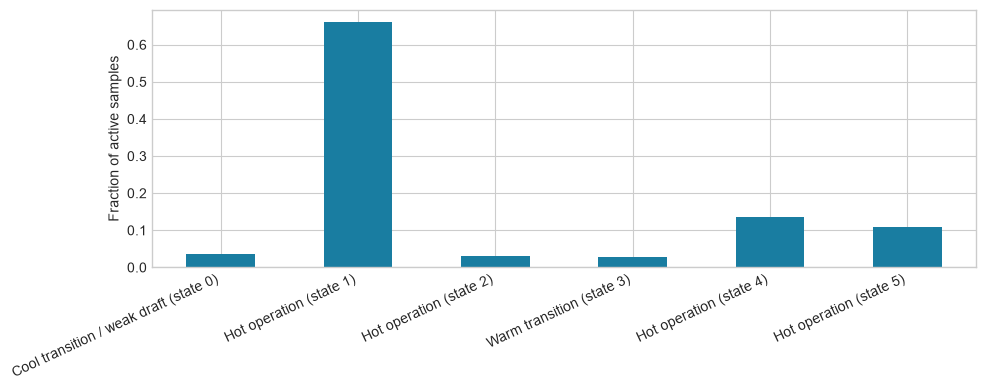

In [5]:
selection = pd.read_csv(ROOT / "sensor_analysis/cluster_selection.csv")
clusters = pd.read_csv(ROOT / "sensor_analysis/clusters_summary.csv")
labels = pd.read_csv(ROOT / "sensor_analysis/sample_labels.csv.gz", index_col=0, parse_dates=True)
display(selection.round(3))
cols = ["state", "state_name", "samples", "frequency_fraction", "episodes", "median_duration_minutes", "Cyclone_Inlet_Gas_Temp_median", "Cyclone_Inlet_Draft_median"]
display(clusters[cols].round(2))
active = labels[labels.state >= 0]
anomaly_rate = active.groupby("state").anomaly.mean().rename("anomaly_fraction")
display(anomaly_rate.to_frame().round(4))
ax = clusters.plot.bar(x="state_name", y="frequency_fraction", legend=False, figsize=(10,4), color="#197da1")
ax.set_ylabel("Fraction of active samples"); ax.set_xlabel(""); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()


## 4. State-relative anomalies

Within each state, robust median absolute deviations identify unusual sensor values. Consecutive flags become events. The selected plots and before/during measurements support hypotheses that still require maintenance records.


In [6]:
anomalies = pd.read_csv(ROOT / "sensor_analysis/anomalous_periods.csv", parse_dates=["start", "end"])
print(f"Candidate events: {len(anomalies):,}")
display(anomalies.nlargest(10, "peak_score"))
display(Markdown((ROOT / "sensor_analysis/anomaly_cases.md").read_text(encoding="utf-8")[:6000]))


Candidate events: 926


,start,end,duration_minutes,state,variables,peak_score
541,2018-09-15 08:35:00,2018-09-15 08:50:00,15,3,Cyclone_cone_draft;Cyclone_Outlet_Gas_draft;Cy...,63.686025
365,2018-05-03 21:05:00,2018-05-03 21:15:00,10,4,Cyclone_Inlet_Gas_Temp;Cyclone_Material_Temp;C...,44.402797
366,2018-05-03 21:20:00,2018-05-03 21:25:00,5,4,Cyclone_Inlet_Gas_Temp;Cyclone_Material_Temp;C...,44.402797
857,2019-11-19 00:20:00,2019-11-19 00:30:00,10,4,Cyclone_Inlet_Gas_Temp;Cyclone_Inlet_Draft;Cyc...,42.910941
498,2018-07-15 21:15:00,2018-07-15 23:40:00,145,4,Cyclone_Inlet_Gas_Temp;Cyclone_Gas_Outlet_Temp...,39.354718
288,2018-02-24 09:15:00,2018-02-24 09:35:00,20,4,Cyclone_Inlet_Gas_Temp;Cyclone_Inlet_Draft;Cyc...,39.354213
289,2018-02-24 09:40:00,2018-02-24 09:45:00,5,4,Cyclone_Inlet_Gas_Temp;Cyclone_Inlet_Draft;Cyc...,39.354213
290,2018-02-24 09:50:00,2018-02-24 10:20:00,30,4,Cyclone_Inlet_Gas_Temp;Cyclone_Material_Temp;C...,39.354213
681,2019-03-28 21:15:00,2019-03-28 21:20:00,5,4,Cyclone_Inlet_Gas_Temp;Cyclone_Inlet_Draft;Cyc...,39.354213
693,2019-04-07 20:10:00,2019-04-07 20:55:00,45,4,Cyclone_Inlet_Gas_Temp;Cyclone_Gas_Outlet_Temp...,39.354213


# Selected anomaly investigations

Comparisons use the 30 minutes before each event and the event median. These are hypotheses, not causal diagnoses.

## Event 1: 2018-09-15 08:35:00

Duration: 15 minutes. State at onset: 3. Peak state-relative robust score: 63.7.

- Cyclone_Inlet_Gas_Temp: before 893.54, during 829.90, change -63.64.
- Cyclone_Material_Temp: before 982.89, during 1092.81, change +109.91.
- Cyclone_Outlet_Gas_draft: before -227.79, during -66.15, change +161.64.
- Cyclone_cone_draft: before -233.42, during 137.39, change +370.81.
- Cyclone_Gas_Outlet_Temp: before 854.07, during 826.45, change -27.62.
- Cyclone_Inlet_Draft: before -180.21, during -38.13, change +142.08.

Hypothesis: A coupled thermal and draft transient is consistent with a change in gas flow or operating regime. State before/after: 5/3. Check the annotated plot for ordering within the five-minute sampling resolution. Maintenance records, fan status and calibration checks are needed to distinguish a process event from an instrument fault. No causal direction is established.

## Event 2: 2018-05-03 21:05:00

Duration: 10 minutes. State at onset: 4. Peak state-relative robust score: 44.4.

- Cyclone_Inlet_Gas_Temp: before 896.88, during 0.00, change -896.88.
- Cyclone_Material_Temp: before 928.36, during 898.00, change -30.37.
- Cyclone_Outlet_Gas_draft: before -240.95, during -240.63, change +0.31.
- Cyclone_cone_draft: before -219.64, during -224.80, change -5.16.
- Cyclone_Gas_Outlet_Temp: before 870.35, during 873.71, change +3.37.
- Cyclone_Inlet_Draft: before -185.93, during -186.81, change -0.88.

Hypothesis: A localized instrument excursion or sensor calibration issue is plausible when the implicated signal changes more than the other sensors. State before/after: 1/5. Check the annotated plot for ordering within the five-minute sampling resolution. Maintenance records, fan status and calibration checks are needed to distinguish a process event from an instrument fault. No causal direction is established.

## Event 3: 2019-11-19 00:20:00

Duration: 10 minutes. State at onset: 4. Peak state-relative robust score: 42.9.

- Cyclone_Inlet_Gas_Temp: before 884.12, during 29.55, change -854.57.
- Cyclone_Material_Temp: before 960.19, during 931.06, change -29.13.
- Cyclone_Outlet_Gas_draft: before -280.71, during -284.09, change -3.38.
- Cyclone_cone_draft: before -237.55, during -240.36, change -2.81.
- Cyclone_Gas_Outlet_Temp: before 945.31, during 919.44, change -25.87.
- Cyclone_Inlet_Draft: before -221.43, during -234.88, change -13.45.

Hypothesis: A localized instrument excursion or sensor calibration issue is plausible when the implicated signal changes more than the other sensors. State before/after: 4/5. Check the annotated plot for ordering within the five-minute sampling resolution. Maintenance records, fan status and calibration checks are needed to distinguish a process event from an instrument fault. No causal direction is established.

## Event 4: 2018-07-15 21:15:00

Duration: 145 minutes. State at onset: 4. Peak state-relative robust score: 39.4.

- Cyclone_Inlet_Gas_Temp: before 912.04, during 99.99, change -812.05.
- Cyclone_Material_Temp: before 951.65, during 936.70, change -14.95.
- Cyclone_Outlet_Gas_draft: before -238.80, during -243.06, change -4.26.
- Cyclone_cone_draft: before -241.26, during -248.27, change -7.01.
- Cyclone_Gas_Outlet_Temp: before 927.33, during 908.01, change -19.32.
- Cyclone_Inlet_Draft: before -185.08, during -191.89, change -6.81.

Hypothesis: A localized instrument excursion or sensor calibration issue is plausible when the implicated signal changes more than the other sensors. State before/after: 1/5. Check the annotated plot for ordering within the five-minute sampling resolution. Maintenance records, fan status and calibration checks are needed to distinguish a process event from an instrument fault. No causal direction is established.


## 5. Twelve forecast horizons

The test split is chronological. Persistence predicts the value at the forecast origin; gradient boosting uses lag and rolling features available at that origin. The one-hour target is twelve five-minute steps ahead.


,horizon_steps,method,MAE,RMSE,n,selected_leaves
24,overall,persistence,11.42,20.65,901296,NaN
25,overall,gradient_boosting,10.01,17.44,901296,NaN


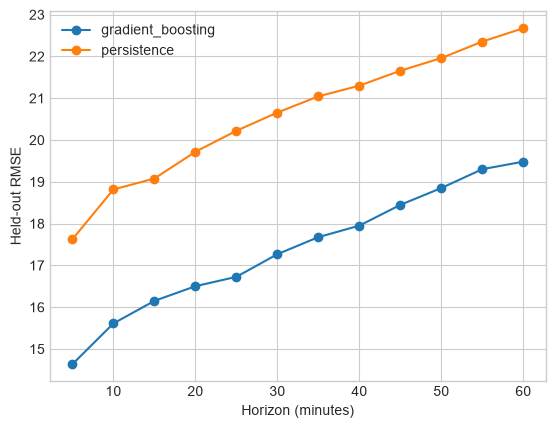

In [7]:
metrics = pd.read_csv(ROOT / "sensor_analysis/forecast_metrics.csv")
display(metrics[metrics.horizon_steps.astype(str).eq("overall")].round(2))
for model, part in metrics[~metrics.horizon_steps.astype(str).eq("overall")].groupby("method"):
    plt.plot(part.horizon_steps.astype(int)*5, part.RMSE, marker="o", label=model)
plt.xlabel("Horizon (minutes)"); plt.ylabel("Held-out RMSE"); plt.legend(); plt.show()


## 6. Cited document retrieval

The supplied 11 PDFs produce 382 indexed chunks. Run `python document_qa/prototype/rag_prototype.py --rebuild` before the next cell. This cell inspects retrieval and page provenance without loading the generator. For generated answers and excerpts, use the dashboard or prototype CLI.


In [8]:
from document_qa.prototype.rag_prototype import RAG
index_dir = ROOT / "document_qa/prototype/index"
if (index_dir / "vectors.faiss").exists():
    rag = RAG(index_dir)
    evidence, similarity = rag.retrieve("How often does Linatex recommend internal cyclone inspections?")
    print("Top dense similarity:", round(similarity, 3))
    display(pd.DataFrame(evidence)[["document", "page", "text"]])
else:
    print("Build the local index using the command above, then rerun this cell.")


C:\Users\milan\Desktop\Projects\ExactSpace\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/all-MiniLM-L6-v2'.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7006.49it/s]

Top dense similarity: 0.861


,document,page,text
0,sect7a.pdf,6,wear. Linatex recommend internal inspections e...
1,sect7a.pdf,6,components of a Linaex cyclone can be re-lined...
2,sect7a.pdf,6,suction pipe to the cyclone feed pump • Badly ...
3,654b45bb8292f586313470.pdf,17,13 5 ǀ MAINTENANCE Always turn off the filter ...


## 7. Decisions and limitations

- Confirm the 77 shutdown-proxy events against operator and maintenance logs.
- Monitor telemetry loss separately from mechanical downtime.
- Review the six state profiles with process engineers before naming operating conditions.
- Triage high-score anomaly cases using fan status, calibration records, and timestamps.
- The one-hour gradient boosting model improves RMSE from 22.68 to 19.48, but transition periods deserve a separate prospective evaluation.
- The RAG smoke test has two answerable page labels and does not establish production faithfulness.
